# Airbnb Nightly Price Prediction

## Objective

Develop and evaluate machine learning regression models to predict Airbnb nightly listing prices in Stockholm County using property characteristics, geographical location, and amenities.

The notebook follows a reproducible machine learning workflow:

1. Retrieve and prepare Airbnb listing data from PostgreSQL.
2. Split the dataset into training (80%) and testing (20%) subsets.
3. Apply preprocessing and feature engineering using scikit-learn pipelines.
4. Compare regression algorithms, feature configurations, and target transformations using five-fold cross-validation.
5. Optimize promising models through hyperparameter tuning.
6. Evaluate the selected model on the held-out test set using MAE, RMSE, and R².
7. Generate local and global SHAP explanations.
8. Log experiments, the selected model, and SHAP artifacts to MLflow for backend integration.

**Target variable:** Advertised nightly price (SEK).

**Primary evaluation metric:** Mean Absolute Error (MAE).

The model estimates advertised market prices rather than occupancy-maximizing or revenue-maximizing prices.

In [12]:

import os
import json
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mlflow
import mlflow.sklearn
import shap
from scipy.stats import randint

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from sqlalchemy import text

from mlflow_utils import load_config, test_server_connection
from postgre_tools import Users, create_postgres_engine

# Reproducibility
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

# MLflow configuration
EXPERIMENT_NAME = "airbnb-price-prediction"

# Dataset configuration
LISTINGS_LIMIT = None
AMENITIES_LIMIT = None

print("=== ENVIRONMENT ===")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn available")
print("MLflow:", mlflow.__version__)
print("SHAP:", shap.__version__)

print("\n=== CONFIGURATION ===")
print(f"Random state: {RANDOM_STATE}")
print(f"Train/test split: {1 - TEST_SIZE:.0%}/{TEST_SIZE:.0%}")
print(f"Cross-validation folds: {CV_FOLDS}")
print(f"Experiment: {EXPERIMENT_NAME}")


=== ENVIRONMENT ===
Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn available
MLflow: 3.16.0
SHAP: 0.54.1

=== CONFIGURATION ===
Random state: 42
Train/test split: 80%/20%
Cross-validation folds: 5
Experiment: airbnb-price-prediction


## 2. Data Retrieval

The dataset originates from [Inside Airbnb](https://insideairbnb.com/get-the-data/) and contains Airbnb listings in Stockholm County.

The data is stored in PostgreSQL and retrieved using the project's existing database utilities.

Two tables are used:

- **`listings`:** Property characteristics, geographical coordinates, room types, and advertised nightly prices.
- **`listing_amenities`:** Amenities associated with individual listings, linked using the listing identifier.

The complete dataset is retrieved without row limits. Data preprocessing and feature engineering are performed after retrieval.

In [6]:
# Initialize PostgreSQL connection
engine = create_postgres_engine(Users.AIRBNB.load_user())

# Retrieve all listings
listings_df = pd.read_sql_query(
    text("SELECT * FROM listings"),
    engine
)

# Retrieve all amenities
listing_amenities_df = pd.read_sql_query(
    text("SELECT listing_id, amenity FROM listing_amenities"),
    engine
)

# Basic dataset validation
required_listing_columns = {
    "id",
    "price",
    "room_type",
    "accommodates",
    "bedrooms",
    "latitude",
    "longitude"
}

required_amenity_columns = {
    "listing_id",
    "amenity"
}

assert required_listing_columns.issubset(listings_df.columns), \
    "Missing required listing columns"

assert required_amenity_columns.issubset(listing_amenities_df.columns), \
    "Missing required amenity columns"

assert listings_df["id"].is_unique, \
    "Duplicate listing IDs detected"

print("=== DATA RETRIEVAL ===")
print(f"Listings: {len(listings_df):,}")
print(f"Listing attributes: {listings_df.shape[1]}")
print(f"Amenity records: {len(listing_amenities_df):,}")
print(
    f"Unique amenities: "
    f"{listing_amenities_df['amenity'].nunique():,}"
)

print("\n=== TARGET VARIABLE ===")
print(f"Missing prices: {listings_df['price'].isna().sum():,}")
print(f"Valid positive prices: {(listings_df['price'] > 0).sum():,}")

print("\nData retrieval completed successfully.")


=== DATA RETRIEVAL ===
Listings: 4,806
Listing attributes: 36
Amenity records: 103,363
Unique amenities: 50

=== TARGET VARIABLE ===
Missing prices: 1,542
Valid positive prices: 3,264

Data retrieval completed successfully.


## 3. Data Preparation

Listings without a valid positive nightly price are excluded because they cannot be used as labeled observations for supervised regression.

The amenities table is aggregated by listing ID to construct an `amenity_count` feature, representing the number of distinct amenities associated with each property.

Listings are then matched with their amenity counts using the listing identifier.

Missing feature values are retained at this stage. Imputation, scaling, and categorical encoding will be performed within scikit-learn pipelines fitted exclusively on training data.

In [7]:
# Keep listings with valid, positive nightly prices
priced_df = listings_df.loc[
    listings_df["price"].notna()
    & (listings_df["price"] > 0)
].copy()

# Count distinct amenities for each listing
amenity_counts = (
    listing_amenities_df
    .groupby("listing_id")["amenity"]
    .nunique()
    .rename("amenity_count")
)

# Join amenity counts to listings
model_df = priced_df.merge(
    amenity_counts,
    left_on="id",
    right_index=True,
    how="left",
    validate="one_to_one"
)

# Validate the resulting dataset
assert len(model_df) == len(priced_df), \
    "Unexpected row count after amenity join"

assert model_df["id"].is_unique, \
    "Duplicate listing IDs detected"

assert model_df["price"].gt(0).all(), \
    "Invalid target prices detected"

print("=== PREPARED DATASET ===")
print(f"Listings: {len(model_df):,}")
print(f"Attributes: {model_df.shape[1]}")
print(f"Listings without amenities: {model_df['amenity_count'].isna().sum()}")

print("\n=== TARGET DISTRIBUTION ===")
print(
    model_df["price"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
    .round(2)
    .to_string()
)

print("\n=== AMENITY COUNT ===")
print(model_df["amenity_count"].describe().round(2).to_string())


=== PREPARED DATASET ===
Listings: 3,264
Attributes: 37
Listings without amenities: 1

=== TARGET DISTRIBUTION ===
count     3264.00
mean      2388.14
std       2101.20
min         32.47
25%       1141.33
50%       1940.00
75%       3083.25
95%       5550.50
99%       9149.98
max      40000.00

=== AMENITY COUNT ===
count    3263.00
mean       21.88
std        10.69
min         1.00
25%        12.00
50%        23.00
75%        31.00
max        45.00


## 4. Feature Configuration and Data Splitting

Multiple feature configurations are evaluated to determine which property characteristics contribute to nightly price prediction.

Three configurations are considered:

- **Basic:** Accommodation capacity, bedrooms, geographical coordinates, and room type.
- **Extended:** Additional property characteristics, including beds, bathrooms, property type, and amenity count.
- **Selected:** The six-feature configuration identified during preliminary experimentation.

The dataset is divided into 80% training and 20% testing using a fixed random seed for reproducibility.

The training set is used for cross-validation, model comparison, feature selection, and hyperparameter tuning. The test set remains untouched until the final model has been selected.

In [8]:
# Define candidate feature configurations
FEATURE_SETS = {
    "basic": [
        "accommodates",
        "bedrooms",
        "latitude",
        "longitude",
        "room_type",
    ],

    "extended": [
        "accommodates",
        "bedrooms",
        "beds",
        "bathrooms",
        "latitude",
        "longitude",
        "amenity_count",
        "room_type",
        "property_type",
    ],

    "selected": [
        "accommodates",
        "bedrooms",
        "latitude",
        "longitude",
        "amenity_count",
        "room_type",
    ],
}

# Identify all features used across configurations
ALL_FEATURES = list(dict.fromkeys(
    feature
    for features in FEATURE_SETS.values()
    for feature in features
))

# Validate feature availability
missing_features = set(ALL_FEATURES) - set(model_df.columns)

assert not missing_features, \
    f"Missing dataset features: {missing_features}"

# Prepare features and target
X = model_df[ALL_FEATURES].copy()
y = model_df["price"].copy()

# Split once, ensuring identical observations for all models
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("=== TRAIN/TEST SPLIT ===")
print(f"Training observations: {len(X_train):,}")
print(f"Testing observations: {len(X_test):,}")

print("\n=== FEATURE CONFIGURATIONS ===")

for name, features in FEATURE_SETS.items():
    print(f"{name}: {len(features)} features")
    print(f"  {features}")

print("\n=== TARGET DISTRIBUTION ===")

target_summary = pd.DataFrame({
    "Training": y_train.describe(),
    "Testing": y_test.describe()
}).round(2)

print(target_summary.to_string())

# Validate split
assert set(X_train.index).isdisjoint(set(X_test.index)), \
    "Training and testing sets overlap"

assert len(X_train) + len(X_test) == len(model_df), \
    "Unexpected number of observations"

print("\nTrain/test split validated successfully.")


=== TRAIN/TEST SPLIT ===
Training observations: 2,611
Testing observations: 653

=== FEATURE CONFIGURATIONS ===
basic: 5 features
  ['accommodates', 'bedrooms', 'latitude', 'longitude', 'room_type']
extended: 9 features
  ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'latitude', 'longitude', 'amenity_count', 'room_type', 'property_type']
selected: 6 features
  ['accommodates', 'bedrooms', 'latitude', 'longitude', 'amenity_count', 'room_type']

=== TARGET DISTRIBUTION ===
       Training   Testing
count   2611.00    653.00
mean    2392.35   2371.29
std     2125.52   2002.47
min       32.47    111.36
25%     1141.33   1142.00
50%     1940.14   1853.00
75%     3106.75   2990.00
max    40000.00  25714.29

Train/test split validated successfully.


## 5. Preprocessing Pipeline

Data preprocessing is implemented using scikit-learn's `Pipeline` and `ColumnTransformer` to ensure consistent transformations across regression models.

Numerical features are processed using median imputation and standard scaling. Missing-value indicators are added to preserve information about missing observations.

Categorical features are processed using most-frequent imputation and one-hot encoding. Infrequent categories are grouped to reduce dimensionality.

All transformations are fitted exclusively on the training portion of each cross-validation fold, preventing information leakage from validation and test observations.

In [9]:
# Features requiring categorical encoding
CATEGORICAL_FEATURES = {
    "room_type",
    "property_type",
}

def build_preprocessor(features):
    """
    Build a preprocessing pipeline for a given feature set.

    Parameters
    ----------
    features : list[str]
        Input features to include.

    Returns
    -------
    ColumnTransformer
        Numerical and categorical preprocessing pipeline.
    """

    numeric_features = [
        feature for feature in features
        if feature not in CATEGORICAL_FEATURES
    ]

    categorical_features = [
        feature for feature in features
        if feature in CATEGORICAL_FEATURES
    ]

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=10,
            sparse_output=False
        ))
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ],
        verbose_feature_names_out=False
    )


# Verify preprocessing configurations without fitting
print("=== PREPROCESSING CONFIGURATIONS ===")

for name, features in FEATURE_SETS.items():

    preprocessor = build_preprocessor(features)

    numeric = [
        f for f in features
        if f not in CATEGORICAL_FEATURES
    ]

    categorical = [
        f for f in features
        if f in CATEGORICAL_FEATURES
    ]

    print(f"\n{name.upper()}")
    print(f"Numerical: {numeric}")
    print(f"Categorical: {categorical}")

print("\nPreprocessing configurations initialized successfully.")


=== PREPROCESSING CONFIGURATIONS ===

BASIC
Numerical: ['accommodates', 'bedrooms', 'latitude', 'longitude']
Categorical: ['room_type']

EXTENDED
Numerical: ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'latitude', 'longitude', 'amenity_count']
Categorical: ['room_type', 'property_type']

SELECTED
Numerical: ['accommodates', 'bedrooms', 'latitude', 'longitude', 'amenity_count']
Categorical: ['room_type']

Preprocessing configurations initialized successfully.


## 6. Model Training and Comparison

Four regression algorithms are evaluated: Dummy Regressor, Ridge Regression, Random Forest, and Histogram Gradient Boosting.

Each algorithm is evaluated with three feature configurations using five-fold cross-validation on the training dataset.

The models are compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

MAE is the primary metric for model selection because it expresses the average prediction error in the original price unit (SEK).

All experiment configurations and evaluation metrics are recorded in MLflow for reproducibility and comparison. The held-out test set is excluded from model selection.

In [10]:
# Initial model configurations
MODELS = {
    "dummy": DummyRegressor(
        strategy="median"
    ),

    "ridge": Ridge(
        alpha=1.0
    ),

    "random_forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "hist_gradient_boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ),
}

SCORING = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

CV = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)


def evaluate_model(model_name, model, feature_set_name):
    """
    Evaluate a regression model using five-fold cross-validation
    and log the experiment to MLflow.
    """

    features = FEATURE_SETS[feature_set_name]

    pipeline = Pipeline(steps=[
        ("preprocessor", build_preprocessor(features)),
        ("model", model)
    ])

    with mlflow.start_run(
        run_name=f"{model_name}-{feature_set_name}"
    ) as run:

        cv_results = cross_validate(
            pipeline,
            X_train[features],
            y_train,
            cv=CV,
            scoring=SCORING,
            n_jobs=1
        )

        metrics = {
            "cv_mae": float(-cv_results["test_mae"].mean()),
            "cv_rmse": float(-cv_results["test_rmse"].mean()),
            "cv_r2": float(cv_results["test_r2"].mean()),
        }

        mlflow.log_params({
            "model": model_name,
            "feature_set": feature_set_name,
            "feature_count": len(features),
            "features": ", ".join(features),
            "cv_folds": CV_FOLDS,
            "training_samples": len(X_train),
            **{
                f"model_{key}": value
                for key, value in model.get_params().items()
                if value is not None
            }
        })

        mlflow.log_metrics(metrics)

        return {
            "model": model_name,
            "feature_set": feature_set_name,
            "features": len(features),
            **metrics,
            "run_id": run.info.run_id
        }


print("=== MODEL CONFIGURATIONS ===")

for name, model in MODELS.items():
    print(f"{name}: {type(model).__name__}")

print("\nEvaluation function initialized successfully.")


=== MODEL CONFIGURATIONS ===
dummy: DummyRegressor
ridge: Ridge
random_forest: RandomForestRegressor
hist_gradient_boosting: HistGradientBoostingRegressor

Evaluation function initialized successfully.


In [11]:

# Initialize the existing MLflow configuration
load_config()
test_server_connection()

# Select experiment
mlflow.set_experiment(EXPERIMENT_NAME)

# Store experiment results
experiment_results = []

print("\n=== RUNNING MODEL EXPERIMENTS ===")

for model_name, model in MODELS.items():
    for feature_set_name in FEATURE_SETS:

        print(f"\nTraining: {model_name} | {feature_set_name}")

        result = evaluate_model(
            model_name=model_name,
            model=model,
            feature_set_name=feature_set_name
        )

        experiment_results.append(result)

        print(
            f"MAE: {result['cv_mae']:.2f} SEK | "
            f"RMSE: {result['cv_rmse']:.2f} SEK | "
            f"R²: {result['cv_r2']:.4f}"
        )

# Create comparison table
results_df = (
    pd.DataFrame(experiment_results)
    .sort_values("cv_mae")
    .reset_index(drop=True)
)

print("\n=== MODEL COMPARISON ===")

print(
    results_df[
        ["model", "feature_set", "features",
         "cv_mae", "cv_rmse", "cv_r2"]
    ]
    .round(2)
    .to_string(index=False)
)

print("\n=== BEST INITIAL CONFIGURATION ===")

best_result = results_df.iloc[0]

print(f"Model: {best_result['model']}")
print(f"Feature set: {best_result['feature_set']}")
print(f"CV MAE: {best_result['cv_mae']:.2f} SEK")
print(f"CV RMSE: {best_result['cv_rmse']:.2f} SEK")
print(f"CV R²: {best_result['cv_r2']:.4f}")


Configuration loaded successfully.
MLflow connection successful!
Found 1 experiment(s)

=== RUNNING MODEL EXPERIMENTS ===

Training: dummy | basic
🏃 View run dummy-basic at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/f765fa314b5d4fb688dbb57c202f0149
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2
MAE: 1275.06 SEK | RMSE: 2129.85 SEK | R²: -0.0489

Training: dummy | extended
🏃 View run dummy-extended at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/76cc7b6a98f243268aa5acbfd97382c2
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2
MAE: 1275.06 SEK | RMSE: 2129.85 SEK | R²: -0.0489

Training: dummy | selected
🏃 View run dummy-selected at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/edbc4b93dfa04bedac2f4d313db6fe24
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2
MAE: 1275.06 SEK | RMSE: 2129.85 SEK | R²: -0.0489

Training: ridge | basic
🏃 View run ridge-basic at: https://cu0089.camp.lnu.s

## 7. Hyperparameter Optimization

Random Forest is selected for further optimization based on its cross-validation performance during initial model comparison.

Two feature configurations are retained for tuning:

- **Extended:** Nine property and location features.
- **Selected:** Six features requiring fewer user inputs.

Hyperparameters are optimized using randomized search with five-fold cross-validation.

The search evaluates tree depth, number of estimators, minimum samples per split and leaf, and the number of features considered at each split.

MAE is used as the optimization objective. The results are logged to MLflow and compared to determine the preferred model configuration.

In [13]:
# Random Forest hyperparameter search space
RF_PARAM_DISTRIBUTIONS = {
    "model__n_estimators": randint(100, 401),
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 8),
    "model__max_features": [0.5, 0.75, 1.0],
}

# Number of parameter configurations to evaluate
N_ITER_SEARCH = 20


def tune_random_forest(feature_set_name):
    """
    Optimize Random Forest hyperparameters for a feature set.
    Log the best configuration and CV metrics to MLflow.
    """

    features = FEATURE_SETS[feature_set_name]

    pipeline = Pipeline(steps=[
        ("preprocessor", build_preprocessor(features)),
        ("model", RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=RF_PARAM_DISTRIBUTIONS,
        n_iter=N_ITER_SEARCH,
        scoring=SCORING,
        refit="mae",
        cv=CV,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=1
    )

    with mlflow.start_run(
        run_name=f"random-forest-tuned-{feature_set_name}"
    ) as run:

        search.fit(X_train[features], y_train)

        best_index = search.best_index_
        cv_results = search.cv_results_

        metrics = {
            "cv_mae": float(
                -cv_results["mean_test_mae"][best_index]
            ),
            "cv_rmse": float(
                -cv_results["mean_test_rmse"][best_index]
            ),
            "cv_r2": float(
                cv_results["mean_test_r2"][best_index]
            ),
        }

        mlflow.log_params({
            "model": "RandomForestRegressor",
            "feature_set": feature_set_name,
            "feature_count": len(features),
            "search_method": "RandomizedSearchCV",
            "n_iter": N_ITER_SEARCH,
            "cv_folds": CV_FOLDS,
            **search.best_params_
        })

        mlflow.log_metrics(metrics)

        result = {
            "feature_set": feature_set_name,
            "features": len(features),
            **metrics,
            "best_params": search.best_params_,
            "run_id": run.info.run_id,
            "best_estimator": search.best_estimator_
        }

    return result


print("=== RANDOM FOREST TUNING CONFIGURATION ===")
print(f"Search iterations: {N_ITER_SEARCH}")
print(f"Cross-validation folds: {CV_FOLDS}")
print(f"Configurations to tune: extended, selected")
print(f"Search space: {list(RF_PARAM_DISTRIBUTIONS.keys())}")


=== RANDOM FOREST TUNING CONFIGURATION ===
Search iterations: 20
Cross-validation folds: 5
Configurations to tune: extended, selected
Search space: ['model__n_estimators', 'model__max_depth', 'model__min_samples_split', 'model__min_samples_leaf', 'model__max_features']


In [14]:

# Run hyperparameter optimization for both feature configurations
tuning_results = []

for feature_set_name in ["extended", "selected"]:

    print(f"\n=== TUNING: {feature_set_name.upper()} ===")

    result = tune_random_forest(feature_set_name)
    tuning_results.append(result)

    print("\nBest hyperparameters:")
    for param, value in result["best_params"].items():
        print(f"  {param}: {value}")

    print("\nCross-validation results:")
    print(f"MAE:  {result['cv_mae']:.2f} SEK")
    print(f"RMSE: {result['cv_rmse']:.2f} SEK")
    print(f"R²:   {result['cv_r2']:.4f}")

# Create summary without the fitted model objects
tuning_df = pd.DataFrame([
    {
        "feature_set": result["feature_set"],
        "features": result["features"],
        "cv_mae": result["cv_mae"],
        "cv_rmse": result["cv_rmse"],
        "cv_r2": result["cv_r2"],
        "run_id": result["run_id"],
    }
    for result in tuning_results
]).sort_values("cv_mae").reset_index(drop=True)

print("\n=== HYPERPARAMETER TUNING COMPARISON ===")
print(
    tuning_df.round(2).to_string(index=False)
)

# Identify best tuned configuration
best_tuned_result = min(
    tuning_results,
    key=lambda result: result["cv_mae"]
)

print("\n=== BEST TUNED CONFIGURATION ===")
print("Feature set:", best_tuned_result["feature_set"])
print("CV MAE:", round(best_tuned_result["cv_mae"], 2), "SEK")
print("CV RMSE:", round(best_tuned_result["cv_rmse"], 2), "SEK")
print("CV R²:", round(best_tuned_result["cv_r2"], 4))



=== TUNING: EXTENDED ===
Fitting 5 folds for each of 20 candidates, totalling 100 fits
🏃 View run random-forest-tuned-extended at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/e92e9a36fa724e98b0961df4237ffa5d
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Best hyperparameters:
  model__max_depth: 10
  model__max_features: 0.5
  model__min_samples_leaf: 1
  model__min_samples_split: 7
  model__n_estimators: 352

Cross-validation results:
MAE:  752.78 SEK
RMSE: 1405.93 SEK
R²:   0.5529

=== TUNING: SELECTED ===
Fitting 5 folds for each of 20 candidates, totalling 100 fits
🏃 View run random-forest-tuned-selected at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/bf03db4b1a46467eb1f3eb70f40d280c
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Best hyperparameters:
  model__max_depth: 10
  model__max_features: 0.5
  model__min_samples_leaf: 1
  model__min_samples_split: 7
  model__n_estimators: 352

Cross-validation resul

## 8. Target Transformation

Airbnb nightly prices are right-skewed, with a relatively small number of expensive listings.

To investigate whether target transformation improves prediction performance, the tuned Random Forest configurations are evaluated using both raw nightly prices and logarithmically transformed prices.

The logarithmic transformation is implemented using `TransformedTargetRegressor` with `log1p` and `expm1`.

All evaluation metrics are calculated in the original price scale (SEK). Five-fold cross-validation is performed exclusively on the training dataset.

The preferred configuration is selected based on cross-validation MAE, with RMSE, R², and the number of required input features considered as secondary criteria.

In [15]:

# Start with the existing tuned results
transformation_results = []

for tuned_result in tuning_results:

    feature_set_name = tuned_result["feature_set"]
    features = FEATURE_SETS[feature_set_name]

    # Retain the existing raw-price CV result
    transformation_results.append({
        "feature_set": feature_set_name,
        "target": "raw",
        "features": len(features),
        "cv_mae": tuned_result["cv_mae"],
        "cv_rmse": tuned_result["cv_rmse"],
        "cv_r2": tuned_result["cv_r2"],
        "run_id": tuned_result["run_id"],
    })

    # Wrap the tuned pipeline with a logarithmic target transformation
    log_model = TransformedTargetRegressor(
        regressor=tuned_result["best_estimator"],
        func=np.log1p,
        inverse_func=np.expm1
    )

    with mlflow.start_run(
        run_name=f"random-forest-log-{feature_set_name}"
    ) as run:

        cv_results = cross_validate(
            log_model,
            X_train[features],
            y_train,
            cv=CV,
            scoring=SCORING,
            n_jobs=1
        )

        metrics = {
            "cv_mae": float(-cv_results["test_mae"].mean()),
            "cv_rmse": float(-cv_results["test_rmse"].mean()),
            "cv_r2": float(cv_results["test_r2"].mean()),
        }

        mlflow.log_params({
            "model": "RandomForestRegressor",
            "feature_set": feature_set_name,
            "target_transformation": "log1p",
            "feature_count": len(features),
            "cv_folds": CV_FOLDS,
            **tuned_result["best_params"]
        })

        mlflow.log_metrics(metrics)

        transformation_results.append({
            "feature_set": feature_set_name,
            "target": "log1p",
            "features": len(features),
            **metrics,
            "run_id": run.info.run_id,
        })

# Compare all four configurations
transformation_df = (
    pd.DataFrame(transformation_results)
    .sort_values("cv_mae")
    .reset_index(drop=True)
)

print("=== TARGET TRANSFORMATION COMPARISON ===")

print(
    transformation_df[
        ["feature_set", "target", "features",
         "cv_mae", "cv_rmse", "cv_r2"]
    ]
    .round(2)
    .to_string(index=False)
)

# Select the configuration with the lowest CV MAE
best_configuration = transformation_df.iloc[0]

print("\n=== BEST CONFIGURATION ===")
print("Feature set:", best_configuration["feature_set"])
print("Target transformation:", best_configuration["target"])
print(f"CV MAE: {best_configuration['cv_mae']:.2f} SEK")
print(f"CV RMSE: {best_configuration['cv_rmse']:.2f} SEK")
print(f"CV R²: {best_configuration['cv_r2']:.4f}")


🏃 View run random-forest-log-extended at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/c03845baafce41768251d771229e9650
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2
🏃 View run random-forest-log-selected at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/4db8c9273bcd45afb8eae34ae760ca4b
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2
=== TARGET TRANSFORMATION COMPARISON ===
feature_set target  features  cv_mae  cv_rmse  cv_r2
   extended  log1p         9  716.75  1452.01   0.53
   selected  log1p         6  723.24  1461.76   0.52
   extended    raw         9  752.78  1405.93   0.55
   selected    raw         6  756.49  1421.83   0.54

=== BEST CONFIGURATION ===
Feature set: extended
Target transformation: log1p
CV MAE: 716.75 SEK
CV RMSE: 1452.01 SEK
CV R²: 0.5252


## 9. Final Model Training and Evaluation

The preferred model configuration is selected based on the lowest cross-validation MAE.

The selected pipeline is fitted on the complete training dataset and evaluated on the previously unseen test dataset.

The final evaluation reports MAE, RMSE, R², median absolute error, and mean signed prediction error.

The purpose is to estimate how well the selected model generalizes to unseen Airbnb listings from the same dataset.

The test set is used only for final evaluation and not for model selection or hyperparameter tuning.

In [16]:

from sklearn.base import clone

# Retrieve selected configuration
final_feature_set = best_configuration["feature_set"]
final_target = best_configuration["target"]

final_features = FEATURE_SETS[final_feature_set]

# Locate the corresponding tuned Random Forest
selected_tuned_result = next(
    result for result in tuning_results
    if result["feature_set"] == final_feature_set
)

# Clone tuned pipeline to create a fresh final estimator
final_pipeline = clone(
    selected_tuned_result["best_estimator"]
)

# Apply target transformation if selected
if final_target == "log1p":
    final_model = TransformedTargetRegressor(
        regressor=final_pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )
else:
    final_model = final_pipeline

# Prepare selected features
X_train_final = X_train[final_features].copy()
X_test_final = X_test[final_features].copy()

# Fit selected model on the complete training set
final_model.fit(X_train_final, y_train)

# Evaluate on the held-out test set
y_test_pred = final_model.predict(X_test_final)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

test_median_ae = np.median(
    np.abs(y_test.to_numpy() - y_test_pred)
)

test_bias = np.mean(
    y_test_pred - y_test.to_numpy()
)

print("=== SELECTED MODEL ===")
print(f"Feature set: {final_feature_set}")
print(f"Target transformation: {final_target}")
print(f"Features: {final_features}")

print("\n=== FINAL TEST EVALUATION ===")
print(f"Test observations: {len(y_test):,}")
print(f"MAE:       {test_mae:.2f} SEK")
print(f"RMSE:      {test_rmse:.2f} SEK")
print(f"R²:        {test_r2:.4f}")
print(f"Median AE: {test_median_ae:.2f} SEK")
print(f"Mean bias: {test_bias:.2f} SEK")

print("\n=== CROSS-VALIDATION VS TEST ===")
print(f"{'Metric':<12} {'CV':>12} {'Test':>12}")
print("-" * 38)
print(
    f"{'MAE':<12} "
    f"{best_configuration['cv_mae']:>12.2f} "
    f"{test_mae:>12.2f}"
)
print(
    f"{'RMSE':<12} "
    f"{best_configuration['cv_rmse']:>12.2f} "
    f"{test_rmse:>12.2f}"
)
print(
    f"{'R²':<12} "
    f"{best_configuration['cv_r2']:>12.4f} "
    f"{test_r2:>12.4f}"
)


=== SELECTED MODEL ===
Feature set: extended
Target transformation: log1p
Features: ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'latitude', 'longitude', 'amenity_count', 'room_type', 'property_type']

=== FINAL TEST EVALUATION ===
Test observations: 653
MAE:       728.18 SEK
RMSE:      1506.60 SEK
R²:        0.4331
Median AE: 390.02 SEK
Mean bias: -281.56 SEK

=== CROSS-VALIDATION VS TEST ===
Metric                 CV         Test
--------------------------------------
MAE                716.75       728.18
RMSE              1452.01      1506.60
R²                 0.5252       0.4331


## 10. SHAP Explainability

SHAP (SHapley Additive exPlanations) is used to interpret the selected regression model.

Two types of explanations are generated:

- **Global explanations:** Identify which property characteristics have the greatest average influence on predicted nightly prices.
- **Local explanations:** Show how individual property characteristics contribute positively or negatively to a specific prediction.

A model-agnostic permutation explainer is applied to the complete prediction pipeline. This allows SHAP contributions to be expressed in SEK rather than logarithmic price units.

Categorical features are temporarily represented using numerical codes during SHAP calculations and converted back into their original categories before prediction.

The SHAP background dataset is sampled exclusively from training observations and will be saved alongside the selected model for reproducible backend integration.

In [17]:

# Identify categorical features in the final model
shap_categorical_features = [
    feature for feature in final_features
    if feature in CATEGORICAL_FEATURES
]

# Create categorical mappings using training data only
category_mappings = {
    feature: {
        category: code
        for code, category in enumerate(
            sorted(X_train_final[feature].dropna().unique())
        )
    }
    for feature in shap_categorical_features
}

reverse_category_mappings = {
    feature: {
        code: category
        for category, code in mapping.items()
    }
    for feature, mapping in category_mappings.items()
}


def encode_shap_input(df):
    """Convert categorical features to numeric codes for SHAP."""

    encoded = df[final_features].copy()

    for feature, mapping in category_mappings.items():
        encoded[feature] = encoded[feature].map(mapping)

    return encoded.astype(float)


def predict_for_shap(X):
    """Decode SHAP inputs and predict prices in SEK."""

    df = pd.DataFrame(
        X,
        columns=final_features
    ).copy()

    for feature, mapping in reverse_category_mappings.items():
        codes = np.rint(df[feature]).astype(int)

        df[feature] = [
            mapping[code] for code in codes
        ]

    return final_model.predict(df)


# Create reproducible background data from training set
shap_background_original = X_train_final.sample(
    n=30,
    random_state=RANDOM_STATE
)

shap_background = encode_shap_input(
    shap_background_original
)

# Verify encoding and prediction consistency
sample_original = X_train_final.sample(
    n=10,
    random_state=123
)

sample_encoded = encode_shap_input(sample_original)

original_predictions = final_model.predict(sample_original)
wrapped_predictions = predict_for_shap(sample_encoded)

print("=== SHAP CONFIGURATION ===")
print("Features:", final_features)
print("Background shape:", shap_background.shape)

print("\n=== CATEGORICAL MAPPINGS ===")
for feature, mapping in category_mappings.items():
    print(f"{feature}: {len(mapping)} categories")

print("\n=== PREDICTION CONSISTENCY ===")
print(
    "Predictions match:",
    np.allclose(
        original_predictions,
        wrapped_predictions,
        rtol=1e-10,
        atol=1e-8
    )
)

print(
    "Maximum difference:",
    np.max(np.abs(
        original_predictions - wrapped_predictions
    ))
)


=== SHAP CONFIGURATION ===
Features: ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'latitude', 'longitude', 'amenity_count', 'room_type', 'property_type']
Background shape: (30, 9)

=== CATEGORICAL MAPPINGS ===
room_type: 3 categories
property_type: 40 categories

=== PREDICTION CONSISTENCY ===
Predictions match: True
Maximum difference: 1.1823431123048067e-11


In [18]:

# Initialize the model-agnostic SHAP explainer
shap_explainer = shap.Explainer(
    predict_for_shap,
    shap_background,
    algorithm="permutation",
    seed=RANDOM_STATE
)

# Select reproducible training observations for explanation
X_shap_original = X_train_final.sample(
    n=5,
    random_state=123
)

X_shap = encode_shap_input(X_shap_original)

# Calculate SHAP values
shap_values = shap_explainer(
    X_shap,
    max_evals=200
)

# Compare SHAP reconstruction against model predictions
predictions = final_model.predict(X_shap_original)

reconstructed = (
    shap_values.base_values
    + shap_values.values.sum(axis=1)
)

comparison_df = pd.DataFrame({
    "prediction": predictions,
    "shap_reconstruction": reconstructed,
    "difference": np.abs(predictions - reconstructed)
})

print("=== SHAP EXPLANATION VERIFICATION ===")
print("SHAP values shape:", shap_values.values.shape)

print("\n=== PREDICTION RECONSTRUCTION ===")
print(comparison_df.round(4).to_string(index=False))

print("\n=== MAXIMUM RECONSTRUCTION DIFFERENCE ===")
print(f"{comparison_df['difference'].max():.6f} SEK")


=== SHAP EXPLANATION VERIFICATION ===
SHAP values shape: (5, 9)

=== PREDICTION RECONSTRUCTION ===
 prediction  shap_reconstruction  difference
  2949.6540            2949.6540         0.0
  2744.4069            2744.4069         0.0
  2451.9932            2451.9932         0.0
  2989.7367            2989.7367         0.0
  1008.8391            1008.8391         0.0

=== MAXIMUM RECONSTRUCTION DIFFERENCE ===
0.000000 SEK


=== LISTING CHARACTERISTICS ===
accommodates                   5
bedrooms                     3.0
beds                         3.0
bathrooms                    2.0
latitude               59.281693
longitude               18.10451
amenity_count                9.0
room_type        Entire home/apt
property_type        Entire home

=== PRICE PREDICTION ===
Predicted nightly price: 2949.65 SEK

=== SHAP CONTRIBUTIONS ===
      feature           value  shap_value
     bedrooms             3.0  596.245552
 accommodates               5  481.774605
    bathrooms             2.0  148.945486
property_type     Entire home  104.414122
    room_type Entire home/apt   86.559530
         beds             3.0   65.289719
    longitude        18.10451  -94.371599
amenity_count             9.0 -130.896983
     latitude       59.281693 -342.035815


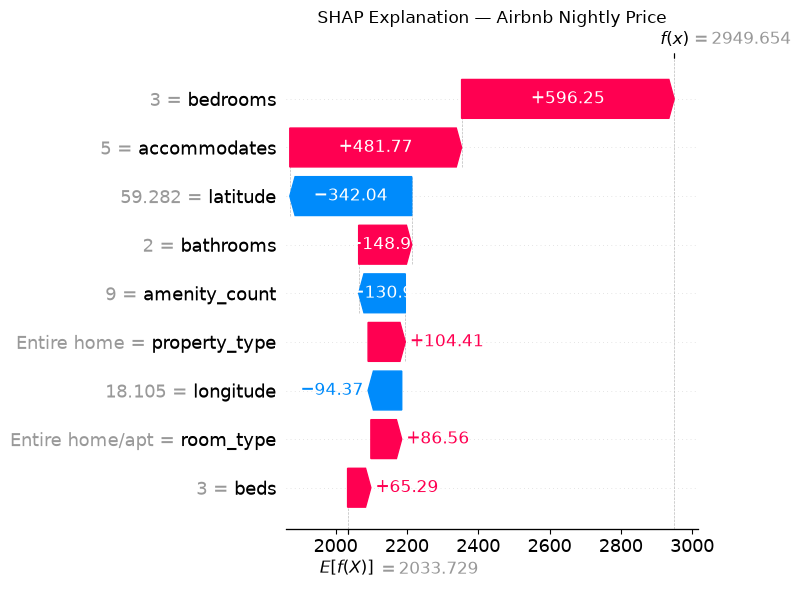

In [19]:

# Select the first explained listing
listing_index = 0

# Retrieve the listing's original characteristics
listing = X_shap_original.iloc[listing_index]

prediction = predictions[listing_index]

# Create contribution summary
local_contributions = (
    pd.DataFrame({
        "feature": final_features,
        "value": listing.values,
        "shap_value": shap_values.values[listing_index]
    })
    .sort_values("shap_value", ascending=False)
)

print("=== LISTING CHARACTERISTICS ===")
print(listing.to_string())

print("\n=== PRICE PREDICTION ===")
print(f"Predicted nightly price: {prediction:.2f} SEK")

print("\n=== SHAP CONTRIBUTIONS ===")
print(local_contributions.to_string(index=False))

# Construct explanation using original feature values
local_explanation = shap.Explanation(
    values=shap_values.values[listing_index],
    base_values=shap_values.base_values[listing_index],
    data=listing.to_numpy(),
    feature_names=final_features
)

# Display waterfall plot
shap.plots.waterfall(
    local_explanation,
    max_display=len(final_features),
    show=False
)

plt.title("SHAP Explanation — Airbnb Nightly Price")
plt.tight_layout()
plt.show()


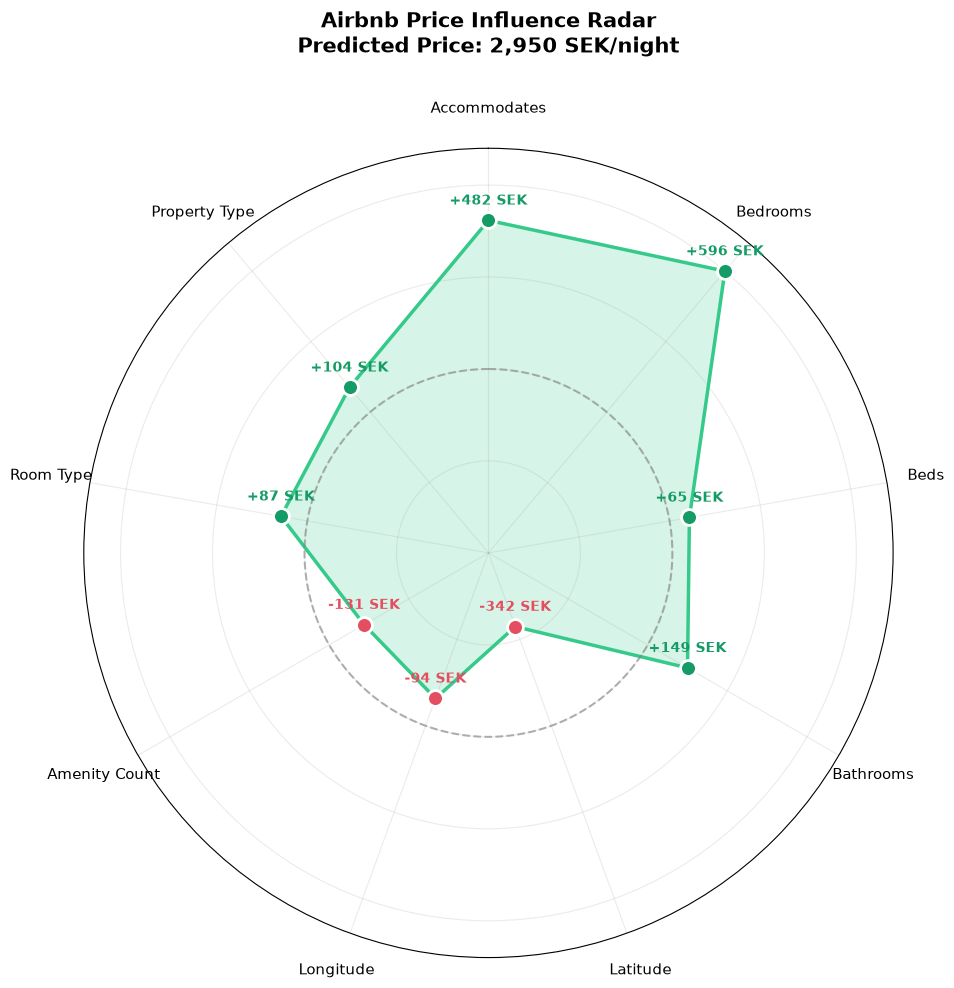

In [21]:

# === SHAP RADAR CHART WITH DATA POINTS ===

listing_index = 0

feature_names = final_features
contributions = shap_values.values[listing_index]

# Normalize SHAP contributions
# 0 = strongest negative, 50 = neutral, 100 = strongest positive
max_abs = np.max(np.abs(contributions))

normalized_values = (
    50 + 50 * contributions / max_abs
)

# Radar coordinates
N = len(feature_names)

angles = np.linspace(
    0, 2 * np.pi, N, endpoint=False
)

# Close polygon
closed_angles = np.append(angles, angles[0])
closed_values = np.append(
    normalized_values,
    normalized_values[0]
)

fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw={"polar": True}
)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Draw polygon
ax.plot(
    closed_angles,
    closed_values,
    color="#35C98A",
    linewidth=2.5,
    zorder=2
)

ax.fill(
    closed_angles,
    closed_values,
    color="#35C98A",
    alpha=0.20,
    zorder=1
)

# Draw neutral reference
ax.plot(
    np.linspace(0, 2 * np.pi, 200),
    np.full(200, 50),
    linestyle="--",
    linewidth=1.5,
    color="gray",
    alpha=0.6
)

# Add a visible point at EVERY corner
for angle, value, contribution in zip(
    angles,
    normalized_values,
    contributions
):
    point_color = (
        "#159B66"
        if contribution >= 0
        else "#E34F60"
    )

    ax.scatter(
        angle,
        value,
        s=130,
        color=point_color,
        edgecolors="white",
        linewidths=2,
        zorder=5
    )

    # Display SHAP contribution near the point
    ax.annotate(
        f"{contribution:+.0f} SEK",
        xy=(angle, value),
        xytext=(0, 14),
        textcoords="offset points",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=point_color,
        zorder=6
    )

# Feature labels
ax.set_xticks(angles)

ax.set_xticklabels(
    [
        feature.replace("_", " ").title()
        for feature in feature_names
    ],
    fontsize=11
)

ax.tick_params(axis="x", pad=18)

# Radial settings
ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_yticklabels([])

ax.grid(alpha=0.25)

# Title
prediction = predictions[listing_index]

plt.title(
    f"Airbnb Price Influence Radar\n"
    f"Predicted Price: {prediction:,.0f} SEK/night",
    fontsize=15,
    fontweight="bold",
    pad=35
)

plt.tight_layout()
plt.show()


## 11. Global SHAP Feature Importance

Local SHAP explanations describe how individual property characteristics contribute to a single price prediction.

To identify broader patterns, SHAP values are calculated for a representative sample of training listings.

Global feature importance is measured using the mean absolute SHAP value for each feature. This represents the average magnitude of its contribution to model predictions, expressed in SEK.

Unlike local explanations, global feature importance does not indicate whether a feature generally increases or decreases predictions. Instead, it measures how strongly the model's predictions depend on that feature.

Global SHAP importance is used to identify the most influential property characteristics and support the design of the application's visual analytics interface.

=== GLOBAL SHAP CONFIGURATION ===
Listings: 100
Features: 9


PermutationExplainer explainer: 101it [01:18,  1.12it/s]                         


=== GLOBAL FEATURE IMPORTANCE ===
      feature  mean_abs_shap_sek
 accommodates             395.78
     bedrooms             332.77
     latitude             260.43
    longitude             214.06
    room_type             147.46
amenity_count              73.60
property_type              40.65
    bathrooms              36.92
         beds              32.23


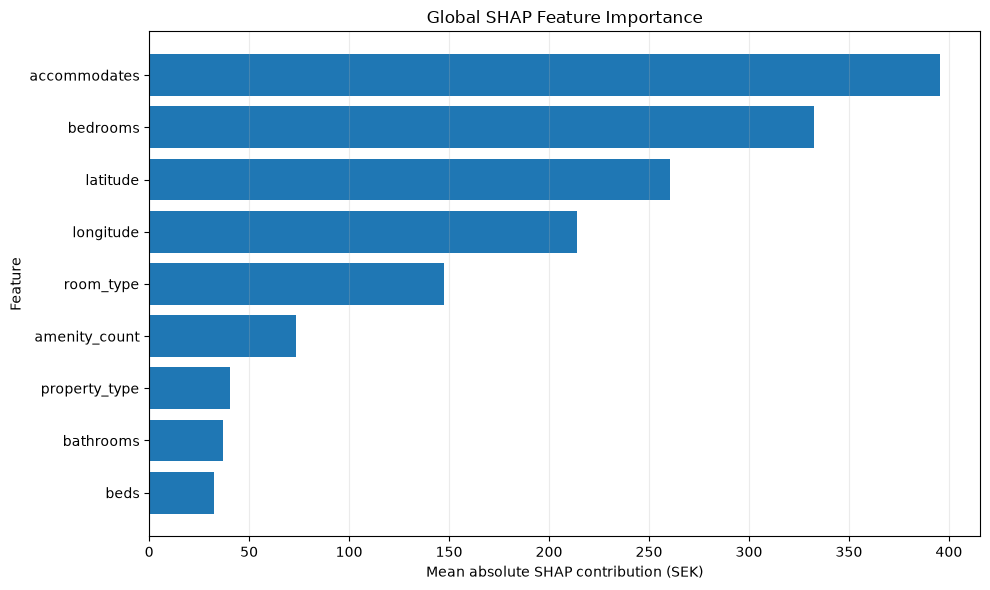


Global SHAP analysis completed successfully.


In [22]:

# === GLOBAL SHAP FEATURE IMPORTANCE ===

GLOBAL_SHAP_SAMPLE_SIZE = 100

# Sample training listings reproducibly
X_shap_global_original = X_train_final.sample(
    n=min(GLOBAL_SHAP_SAMPLE_SIZE, len(X_train_final)),
    random_state=RANDOM_STATE
)

# Encode categorical features for SHAP
X_shap_global = encode_shap_input(
    X_shap_global_original
)

print("=== GLOBAL SHAP CONFIGURATION ===")
print("Listings:", len(X_shap_global))
print("Features:", len(final_features))

# Calculate SHAP values
global_shap_values = shap_explainer(
    X_shap_global,
    max_evals=200
)

# Mean absolute contribution per feature
mean_abs_shap = np.abs(
    global_shap_values.values
).mean(axis=0)

global_importance_df = (
    pd.DataFrame({
        "feature": final_features,
        "mean_abs_shap_sek": mean_abs_shap
    })
    .sort_values(
        "mean_abs_shap_sek",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n=== GLOBAL FEATURE IMPORTANCE ===")
print(
    global_importance_df
    .round(2)
    .to_string(index=False)
)

# Plot global SHAP importance
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    global_importance_df["feature"][::-1],
    global_importance_df["mean_abs_shap_sek"][::-1]
)

ax.set_xlabel("Mean absolute SHAP contribution (SEK)")
ax.set_ylabel("Feature")
ax.set_title("Global SHAP Feature Importance")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# Verify shape
assert global_shap_values.values.shape == (
    len(X_shap_global),
    len(final_features)
)

print("\nGlobal SHAP analysis completed successfully.")
